### Imports

In [1]:
import pandas as pd
import  utils.utils_ipynb as uipy


EXCLUDE_GENERATORS = []
RESULTS_FOLDER = './results_domain_shift'

### Alabama

In [2]:
alabama_income_name = 'alabama_income'
alabama_income_num, alabama_income_cat, alabama_income_label = uipy.get_dataset_columns_name(alabama_income_name)
alabama_income_col_names = alabama_income_num + alabama_income_cat + [alabama_income_label]

alabama_income_fidelity_df = uipy.get_all_fidelity_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_base')
alabama_income_fidelity_expanded_df = uipy.get_expanded_fidelity_df(alabama_income_fidelity_df, alabama_income_col_names)

alabama_income_utility_df = uipy.get_all_utility_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_base')
alabama_income_utility_expanded_df = uipy.get_expanded_utility_df(alabama_income_utility_df)

shift_base = uipy.get_domain_shift_value(RESULTS_FOLDER, alabama_income_name, 'results_base', metric='aux')
alabama_income_privacy_base_df = uipy.get_all_privacy_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_base')
alabama_income_privacy_base_expanded_df = uipy.get_expanded_privacy_df(alabama_income_privacy_base_df)

alabama_privacy_scores = uipy.get_all_mia_scores_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_base')
alabama_privacy_scores_expanded = uipy.get_expanded_mia_scores_df(alabama_privacy_scores)

shift_georgia = uipy.get_domain_shift_value(RESULTS_FOLDER, alabama_income_name, 'results_georgia', metric='aux')
alabama_income_privacy_georgia_df = uipy.get_all_privacy_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_georgia')
alabama_income_privacy_georgia_expanded_df = uipy.get_expanded_privacy_df(alabama_income_privacy_georgia_df)

alabama_privacy_georgia_scores = uipy.get_all_mia_scores_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_georgia')
alabama_privacy_scores_georgia_expanded = uipy.get_expanded_mia_scores_df(alabama_privacy_georgia_scores)

shift_colorado = uipy.get_domain_shift_value(RESULTS_FOLDER, alabama_income_name, 'results_colorado', metric='aux')
alabama_income_privacy_colorado_df = uipy.get_all_privacy_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_colorado')
alabama_income_privacy_colorado_expanded_df = uipy.get_expanded_privacy_df(alabama_income_privacy_colorado_df)

alabama_privacy_colorado_scores = uipy.get_all_mia_scores_results(RESULTS_FOLDER, alabama_income_name, EXCLUDE_GENERATORS, 'results_colorado')
alabama_privacy_scores_colorado_expanded = uipy.get_expanded_mia_scores_df(alabama_privacy_colorado_scores)

#### Fidelidade

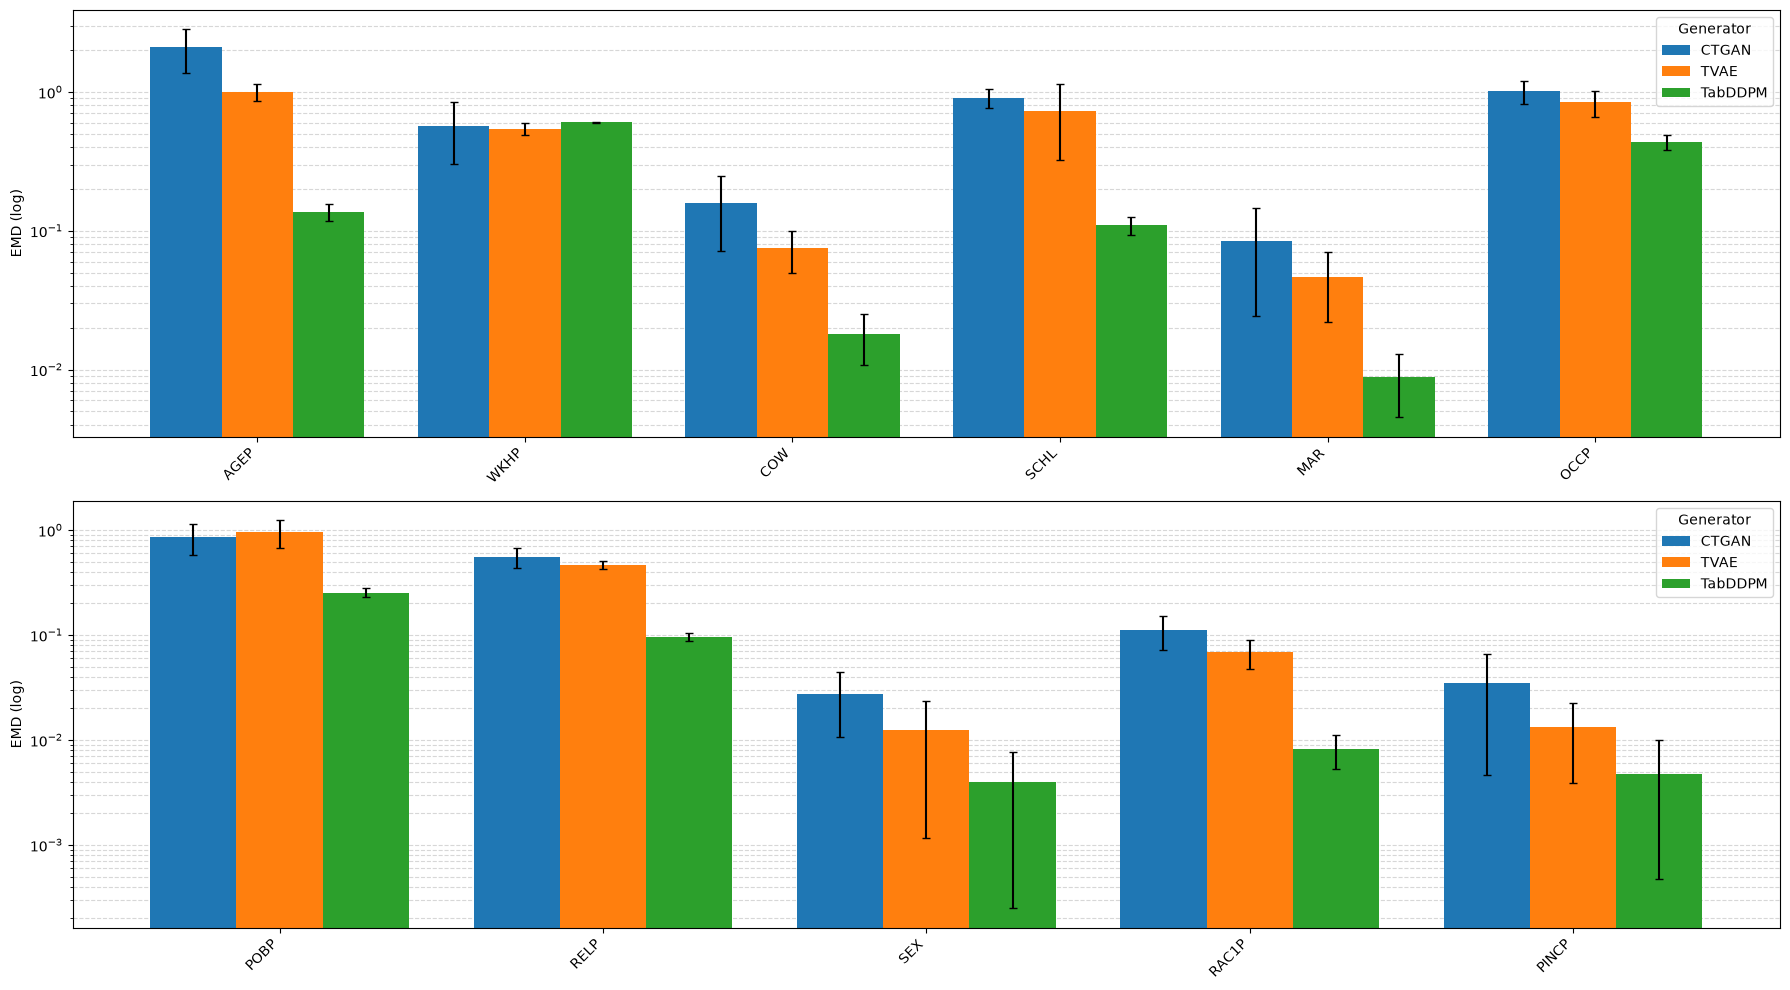

In [3]:
uipy.plot_fidelity_per_column(alabama_income_fidelity_expanded_df, 'EMD', alabama_income_col_names, alabama_income_name, n_parts=2, with_caption=False)

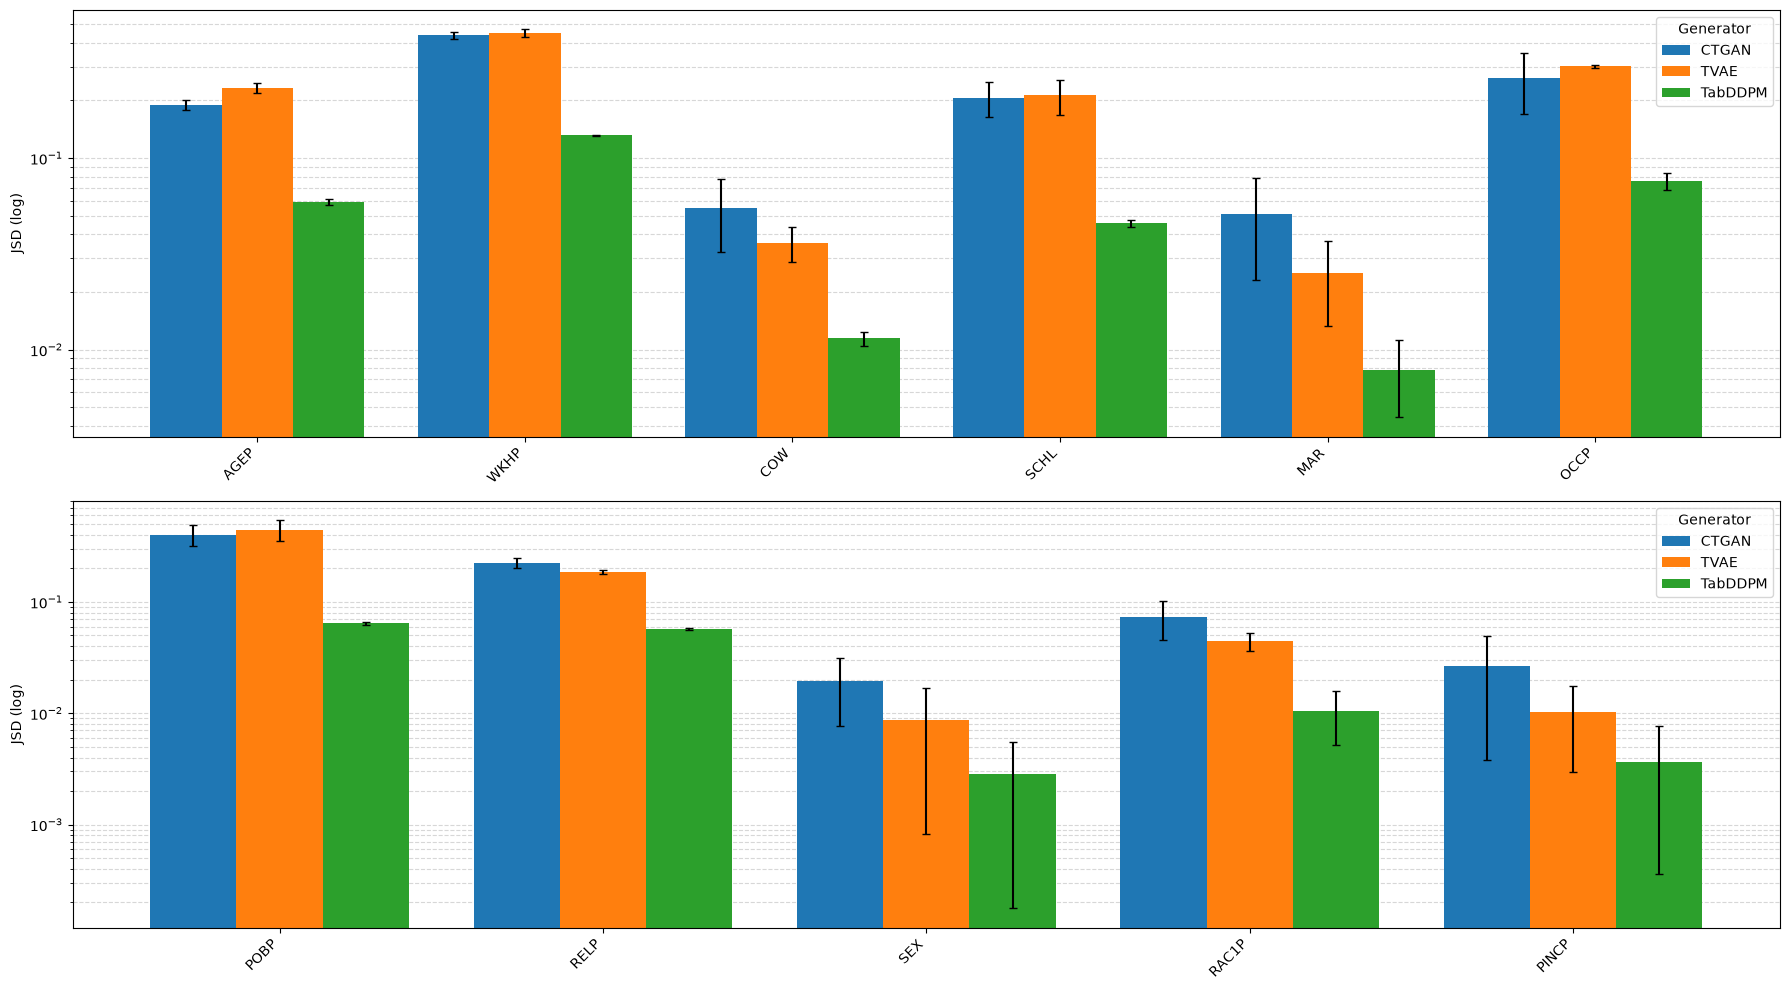

In [4]:
uipy.plot_fidelity_per_column(alabama_income_fidelity_expanded_df, 'JSD', alabama_income_col_names, alabama_income_name, n_parts=2, with_caption=False)

In [5]:
uipy.get_fidelity_table(alabama_income_fidelity_expanded_df)

,EMD,JSD
Gerador,,
CTGAN,0.583 ± 0.046,0.177 ± 0.011
TVAE,0.432 ± 0.072,0.178 ± 0.011
TabDDPM,0.153 ± 0.008,0.043 ± 0.001


#### Utilidade

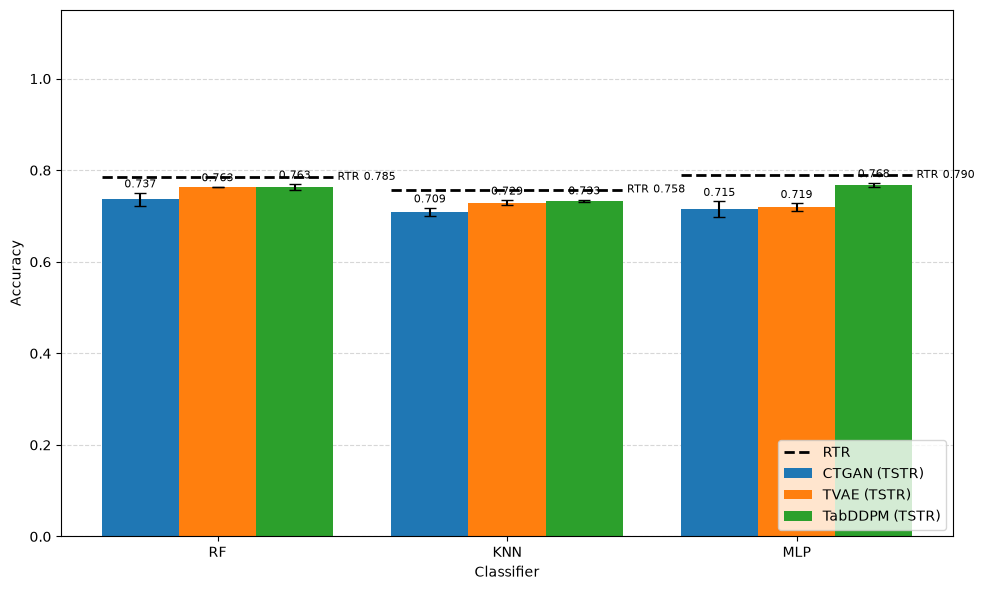

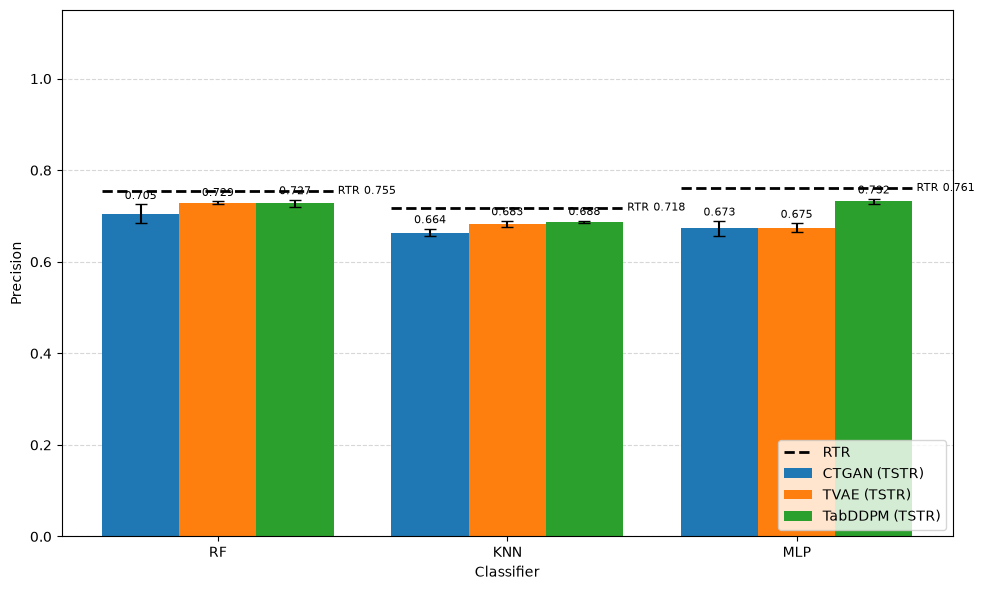

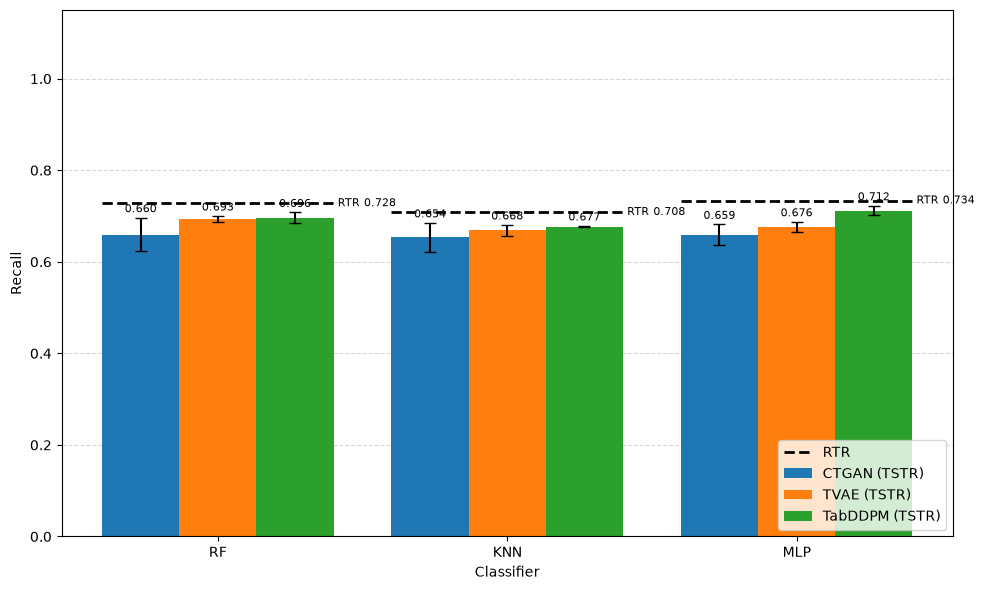

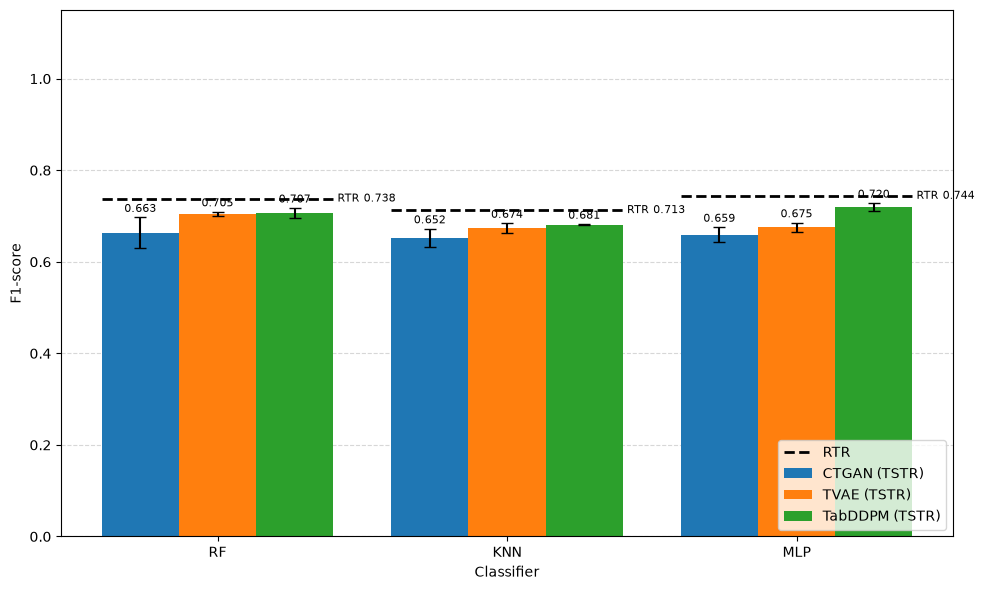

In [6]:
UTILITY_METRICS = ['accuracy', 'precision', 'recall', 'f1_score']

for metric in UTILITY_METRICS:
    uipy.plot_utility(alabama_income_utility_expanded_df, metric, alabama_income_name)


In [7]:
uipy.get_utility_table(alabama_income_utility_expanded_df, metric='f1_score')

,RF,KNN,MLP
Modelo,,,
Baseline (RTR),0.738,0.713,0.744 ± 0.020
CTGAN,0.663 ± 0.034,0.652 ± 0.020,0.659 ± 0.016
TVAE,0.705 ± 0.005,0.674 ± 0.011,0.675 ± 0.010
TabDDPM,0.707 ± 0.011,0.681 ± 0.001,0.720 ± 0.009


#### Privacidade - Gráficos

##### Alabama Referência

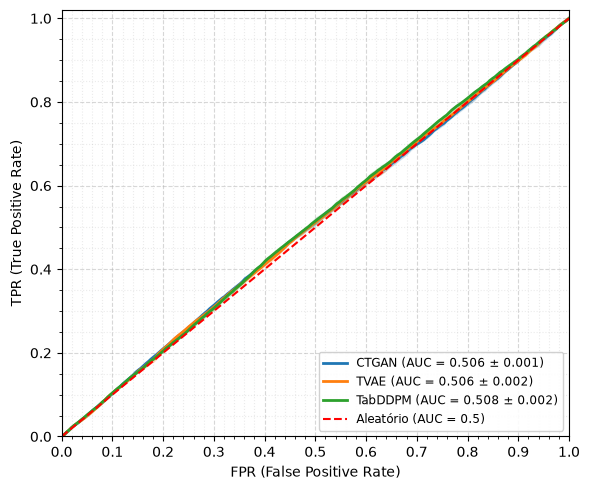

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [8]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_expanded, alabama_income_name, attacks=['FlowMiaGan'], separate_plots=True)

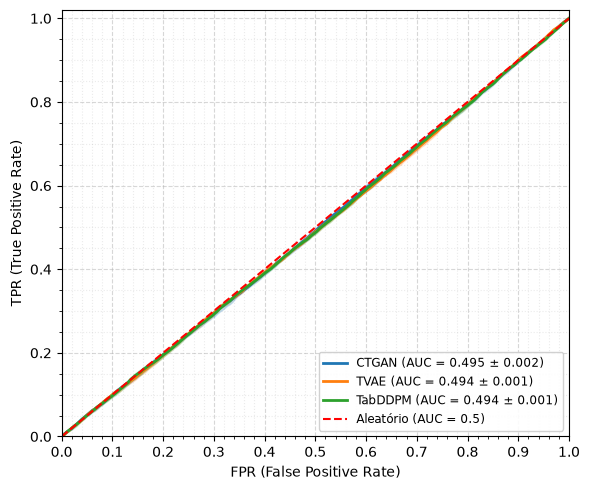

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [9]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_expanded, alabama_income_name, attacks=['Domias'], separate_plots=True)

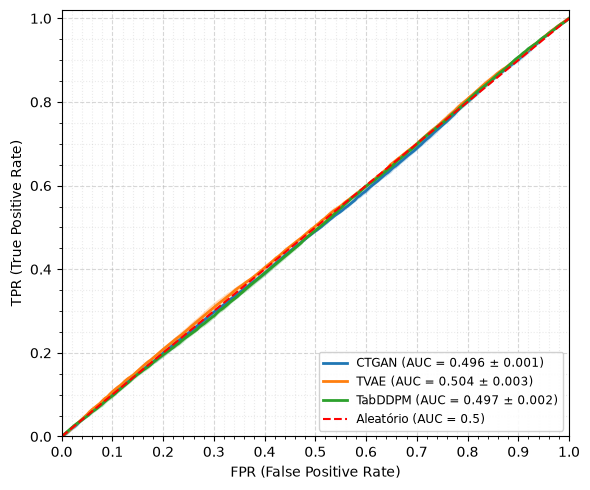

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [10]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_expanded, alabama_income_name, attacks=['DCR'], separate_plots=True)

In [11]:
uipy.get_privacy_table(alabama_income_privacy_base_expanded_df)

Ataque      FlowMiaGan                        Domias                 \
Métrica        AUC-ROC   TPR@FPR=0.10        AUC-ROC   TPR@FPR=0.10   
Gerador                                                               
CTGAN    0.506 ± 0.001  0.102 ± 0.001  0.495 ± 0.002  0.099 ± 0.004   
TVAE     0.506 ± 0.002  0.103 ± 0.001  0.494 ± 0.001  0.100 ± 0.004   
TabDDPM  0.508 ± 0.002  0.104 ± 0.002  0.494 ± 0.001  0.098 ± 0.003   

Ataque             DCR                 
Métrica        AUC-ROC   TPR@FPR=0.10  
Gerador                                
CTGAN    0.496 ± 0.001  0.102 ± 0.003  
TVAE     0.504 ± 0.003  0.108 ± 0.004  
TabDDPM  0.497 ± 0.002  0.100 ± 0.003

##### Georgia Referência

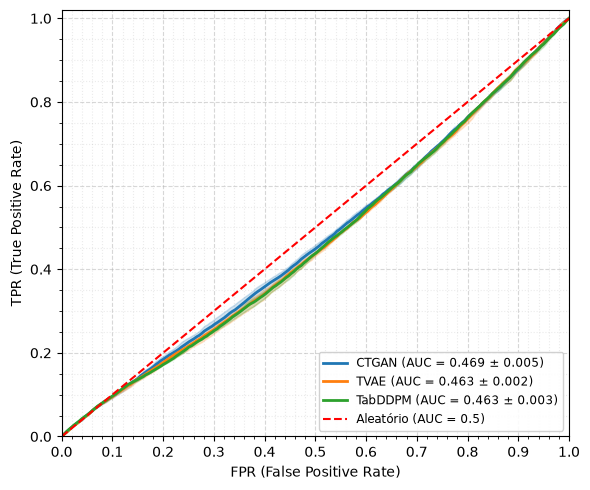

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [12]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_georgia_expanded, alabama_income_name, attacks=['FlowMiaGan'], separate_plots=True)

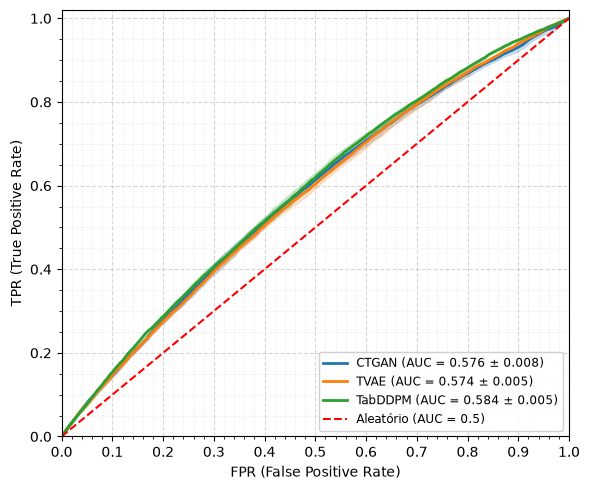

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [13]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_georgia_expanded, alabama_income_name, attacks=['Domias'], separate_plots=True)

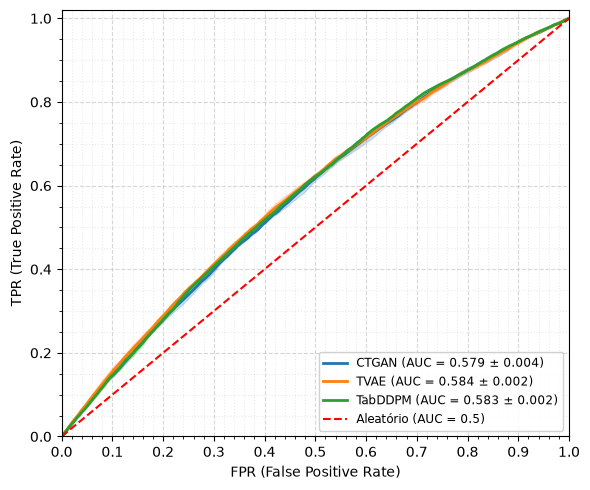

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [14]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_georgia_expanded, alabama_income_name, attacks=['DCR'], separate_plots=True)

In [15]:
uipy.get_privacy_table(alabama_income_privacy_georgia_expanded_df)

Ataque      FlowMiaGan                        Domias                 \
Métrica        AUC-ROC   TPR@FPR=0.10        AUC-ROC   TPR@FPR=0.10   
Gerador                                                               
CTGAN    0.469 ± 0.005  0.096 ± 0.003  0.576 ± 0.008  0.146 ± 0.004   
TVAE     0.463 ± 0.002  0.095 ± 0.003  0.574 ± 0.005  0.146 ± 0.004   
TabDDPM  0.463 ± 0.003  0.096 ± 0.001  0.584 ± 0.005  0.154 ± 0.005   

Ataque             DCR                 
Métrica        AUC-ROC   TPR@FPR=0.10  
Gerador                                
CTGAN    0.579 ± 0.004  0.146 ± 0.004  
TVAE     0.584 ± 0.002  0.156 ± 0.011  
TabDDPM  0.583 ± 0.002  0.148 ± 0.004

##### Colorado Referência

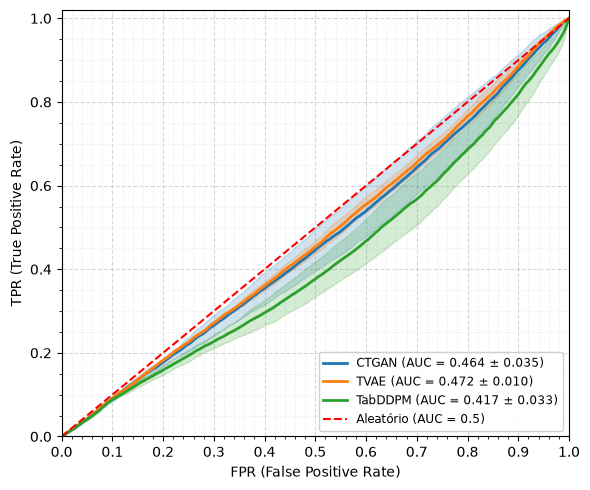

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [16]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_colorado_expanded, alabama_income_name, attacks=['FlowMiaGan'], separate_plots=True)

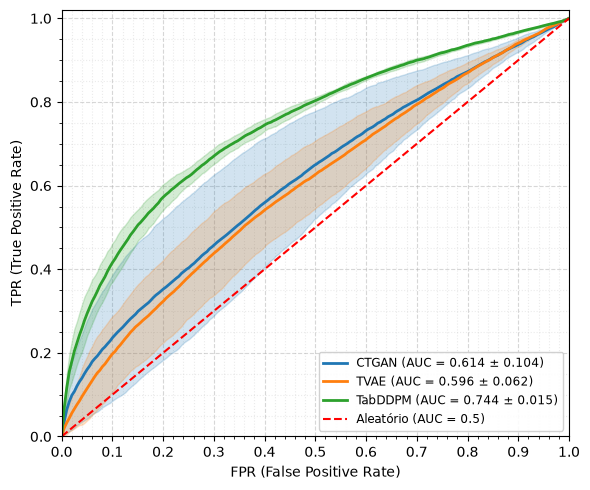

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [17]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_colorado_expanded, alabama_income_name, attacks=['Domias'], separate_plots=True)

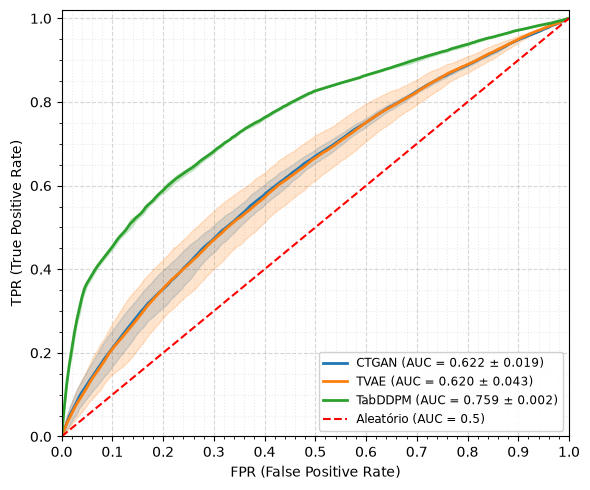

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='FPR (False Positive Rate)', ylabel='TPR (True Positive Rate)'>)]

In [18]:
uipy.plot_mia_roc_curve(alabama_privacy_scores_colorado_expanded, alabama_income_name, attacks=['DCR'], separate_plots=True)

In [19]:
uipy.get_privacy_table(alabama_income_privacy_colorado_expanded_df)

Ataque      FlowMiaGan                        Domias                 \
Métrica        AUC-ROC   TPR@FPR=0.10        AUC-ROC   TPR@FPR=0.10   
Gerador                                                               
CTGAN    0.464 ± 0.035  0.089 ± 0.005  0.614 ± 0.104  0.235 ± 0.150   
TVAE     0.472 ± 0.010  0.092 ± 0.002  0.596 ± 0.062  0.197 ± 0.090   
TabDDPM  0.417 ± 0.033  0.088 ± 0.003  0.744 ± 0.015  0.415 ± 0.046   

Ataque             DCR                 
Métrica        AUC-ROC   TPR@FPR=0.10  
Gerador                                
CTGAN    0.622 ± 0.019  0.223 ± 0.043  
TVAE     0.620 ± 0.043  0.213 ± 0.066  
TabDDPM  0.759 ± 0.002  0.462 ± 0.002

##### Comparação entre os shifts

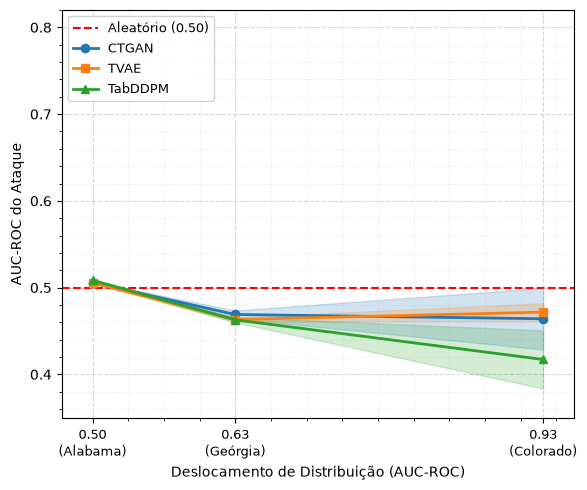

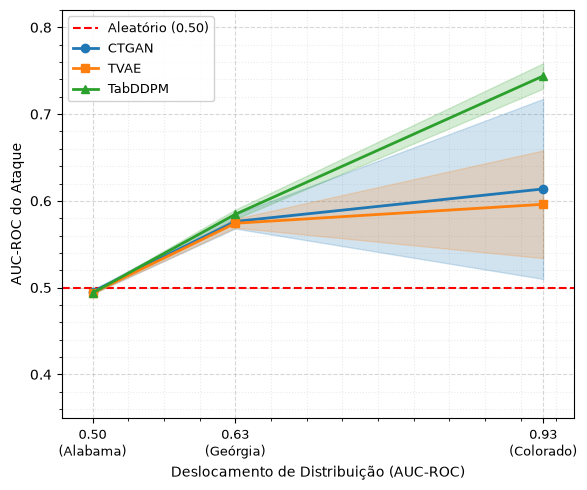

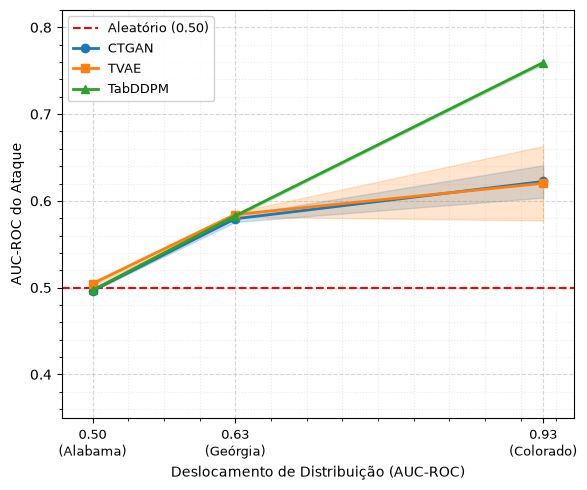

[(<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='Deslocamento de Distribuição (AUC-ROC)', ylabel='AUC-ROC do Ataque'>),
 (<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='Deslocamento de Distribuição (AUC-ROC)', ylabel='AUC-ROC do Ataque'>),
 (<Figure size 600x500 with 1 Axes>,
  <Axes: xlabel='Deslocamento de Distribuição (AUC-ROC)', ylabel='AUC-ROC do Ataque'>)]

In [20]:
data_by_shift = {
    shift_base: alabama_income_privacy_base_expanded_df,
    shift_georgia: alabama_income_privacy_georgia_expanded_df,
    shift_colorado: alabama_income_privacy_colorado_expanded_df,
}
shift_labels = {
    shift_base: "Alabama",
    shift_georgia: "Geórgia",
    shift_colorado: "Colorado",
}

uipy.plot_domain_shift_evolution(
    data_by_shift,
    shift_labels=shift_labels,
    attacks=["FlowMiaGan", "Domias", "DCR"],
    separate_plots=True,
)